# 🏕️ YuruCamp Data Science — Smart Camping Planner & Budget Recommender

> **Project Goal:** Membangun sistem rekomendasi cerdas yang memadukan profil destinasi camp (Jogja–Jateng) dengan kebutuhan perlengkapan serta estimasi anggaran secara end-to-end.

---
### Alur Project (Pipeline)
```
1. Data Ingestion & Reshaping
   ├── Parsing Dataset Spot Camp (Camping Ceria)
   └── Reshaping Dataset Gear (Equipment Recommendation)
2. Data Cleaning & Feature Engineering
   ├── Standardisasi HTM & harga gear (string → numeric)
   └── Ekstraksi tag fasilitas & suasana dari teks bebas
3. Exploratory Data Analysis (EDA)
   ├── Distribusi & statistik spot camp (per wilayah, HTM, fasilitas)
   └── Distribusi harga gear per kategori, perbandingan material
4. Feature Engineering Lanjutan & Segmentasi Spot
   └── K-Means Clustering: Family | Adventure | Scenic
5. Matriks Relasi — Pemetaan Profil Spot ↔ Rekomendasi Gear
6. Smart Camping Planner — Demo Prototype
   └── Input preferensi → Output: Spot Rekomendasi + Gear Checklist + Estimasi Budget
```

---
## 1. Data Ingestion & Reshaping

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import seaborn as sns
import re
import warnings

warnings.filterwarnings('ignore')

# Styling global
sns.set_theme(style='whitegrid', palette='muted')
plt.rcParams['figure.dpi'] = 110
plt.rcParams['font.size'] = 10

print('Libraries loaded successfully')

Libraries loaded successfully


### 1.1 Load & Reshape Dataset Camp Area (Camping Ceria)

In [2]:
PATH_CAMP = r'Database Camp Area ( Jogja -Jateng ) - Camping Ceria.csv'
PATH_GEAR = r'Database List Camp Equipment Recomendation - Camp Equitment.csv'

# Baca raw dengan skiprows agar langsung ke header asli (header ada di baris ke-5, index 4)
df_raw_camp = pd.read_csv(PATH_CAMP, header=None, skiprows=4, encoding='utf-8')

# Ambil kolom yang relevan dan rename
df_camp = df_raw_camp.iloc[:, 1:11].copy()
df_camp.columns = [
    'No', 'Nama', 'col_skip', 'Lokasi',
    'Spot_Menarik', 'Fasilitas', 'HTM_Camp', 'HTM_Parkir',
    'Maps', 'Info_Tambahan'
]
df_camp.drop(columns=['col_skip'], inplace=True)

# Hapus baris yang kosong di kolom 'Nama'
df_camp = df_camp[df_camp['Nama'].notna() & (df_camp['Nama'].astype(str).str.strip() != '')].copy()
df_camp.reset_index(drop=True, inplace=True)

print(f'Dataset Camp: {df_camp.shape[0]} baris, {df_camp.shape[1]} kolom')
df_camp.head(10)

Dataset Camp: 57 baris, 9 kolom


,No,Nama,Lokasi,Spot_Menarik,Fasilitas,HTM_Camp,HTM_Parkir,Maps,Info_Tambahan
0,No.,Nama,Lokasi/Daerah,Spot Menarik,Fasilitas,HTM Camp,HTM Parkir,Maps,Informasi Tambahan
1,1,Potrobayan River Camp,Bantul,Mancing,"Toilet , Warung , Mushola",Rp15.000,-,https://maps.app.goo.gl/pZpEQ47vpyssX24T8,Jangan camp terlalu dekat dengan sungai / luma...
2,2,Hutan Pinus Becici,Bantul,"Panggung City Light , Cafe","Toilet, Listrik di beberapa pohon , Mushola , ...",Rp27.000,Rp5.000,https://maps.app.goo.gl/rPizcxYCshc9XZxa8,NaN
3,3,Watu Mabur Mangunan,Bantul,kabut pagi hari semacam di atas awan,NaN,-,-,https://maps.app.goo.gl/8Yhm4LRsh5E6i4QUA,NaN
4,4,Campground Merbabu,Boyolali,NaN,NaN,NaN,NaN,NaN,NaN
5,5,Campground Bumi Damalung,Boyolali,"view sunrise keren, akses extreme, nanjak tepi...",NaN,NaN,NaN,NaN,NaN
6,6,Embung Batara Sriten,Gunungkidul,NaN,NaN,NaN,NaN,NaN,NaN
7,7,Embung Nglanggeran,Gunungkidul,NaN,NaN,NaN,NaN,NaN,NaN
8,8,Sabana Pantai Baros,Bantul,NaN,NaN,NaN,NaN,NaN,NaN
9,9,Pantai Wediombo,Gunungkidul,NaN,NaN,NaN,NaN,NaN,NaN


### 1.2 Load & Reshape Dataset Gear Equipment (Multi-Blok → Master Table)

In [3]:
raw_gear = pd.read_csv(PATH_GEAR, header=None, encoding='utf-8')

def extract_gear_block(raw_df, row_start, col_start, category_name):
    """
    Mengekstrak blok gear dari posisi (row_start, col_start) di raw CSV.
    Header selalu pada row_start, data mulai row_start+1 sampai baris kosong.
    """
    records = []
    for i in range(row_start + 1, len(raw_df)):
        row = raw_df.iloc[i]
        nama = str(row.iloc[col_start]).strip()
        if nama in ('', 'nan', 'NaN') or nama.startswith(','):
            break
        harga_raw = str(row.iloc[col_start + 3]).strip()
        if harga_raw in ('nan', 'NaN', ''):
            harga_raw = str(row.iloc[col_start + 4]).strip()
        records.append({
            'Kategori':  category_name,
            'Nama':      nama,
            'Ukuran':    str(row.iloc[col_start + 1]).strip(),
            'Material':  str(row.iloc[col_start + 2]).strip(),
            'Harga_Raw': harga_raw,
            'Link':      str(row.iloc[col_start + 4]).strip()
        })
    return records

# Posisi tiap blok di raw CSV (row_start, col_start, nama_kategori)
blok_config = [
    (3,  1, 'Tenda / Tarp Tent'),
    (3,  7, 'Matras'),
    (23, 1, 'Sleeping Bag'),
    (23, 7, 'Cooking Set'),
    (43, 1, 'Meja & Kursi'),
    (43, 7, 'Lampu'),
    (63, 1, 'Carrier / Tas'),
    (63, 7, 'Perlengkapan Lain'),
]

all_gear = []
for row_start, col_start, cat in blok_config:
    all_gear.extend(extract_gear_block(raw_gear, row_start, col_start, cat))

df_gear = pd.DataFrame(all_gear)
df_gear = df_gear[df_gear['Nama'].notna() & ~df_gear['Nama'].isin(['nan', '', 'NaN', 'Nama', 'Harga'])].reset_index(drop=True)

print(f'Dataset Gear: {df_gear.shape[0]} baris, {df_gear.shape[1]} kolom')
df_gear.head(15)

Dataset Gear: 49 baris, 6 kolom


,Kategori,Nama,Ukuran,Material,Harga_Raw,Link
0,Tenda / Tarp Tent,Naturehike Cloud Up 2,2p,"Nylon 20D , frame alloy",1.5 - 1.7 jt,link
1,Tenda / Tarp Tent,Decathlon MH100,2p,"Polyester 210t , frame fiber",400k - 600k,link
2,Tenda / Tarp Tent,Wildshell Navageo,2p,"Polyester 210t , frame alloy",750k,link
3,Tenda / Tarp Tent,Wildshell Sembalun Pro,2p,"Nylon 20D , frame alloy",1.1 - 1.2 jt,link
4,Tenda / Tarp Tent,LWY compass,2p,"Polyester 210t , frame alloy, 1.9 kg",600k - 700k,link
5,Tenda / Tarp Tent,Basic Pollux,2p,"Polyester 190t , frame alloy",684k,link
6,Tenda / Tarp Tent,Big Adventure Tambora,2p,"Polyester 210t , frame alloy",1.1 - 1.3 jt,link
7,Tenda / Tarp Tent,TarpTent Wallhike Calabura,1p,"Nylon 20D , tracking pol",550k,link
8,Tenda / Tarp Tent,TarpTent Wallhike Goramy,2p,"Nylon 20D , tracking pol",650k,link
9,Tenda / Tarp Tent,Flysheet Saffar,3x3 - 3x4,Nylon 20D,150 - 210k,link


---
## 2. Data Cleaning & Feature Engineering

### 2.1 Standardisasi HTM Camp & Parkir (String → Numeric)

In [4]:
def parse_htm(val):
    """Ubah string harga HTM seperti 'Rp15.000', 'Rp25.000,-' menjadi float."""
    if pd.isna(val):
        return np.nan
    s = str(val).strip().lower()
    if s in ('', '-', 'nan', 'gratis', 'seikhlasnya', '0'):
        return 0.0
    s = re.sub(r'[rp\s,\-]', '', s)
    s = s.replace('.', '')
    try:
        return float(s)
    except ValueError:
        return np.nan

df_camp['HTM_Camp_Num']   = df_camp['HTM_Camp'].apply(parse_htm)
df_camp['HTM_Parkir_Num'] = df_camp['HTM_Parkir'].apply(parse_htm)
df_camp['HTM_Total_Num']  = df_camp['HTM_Camp_Num'].fillna(0) + df_camp['HTM_Parkir_Num'].fillna(0)
df_camp['Ada_Maps']       = df_camp['Maps'].notna() & (df_camp['Maps'].astype(str).str.startswith('http'))

print(df_camp[['Nama', 'Lokasi', 'HTM_Camp_Num', 'HTM_Parkir_Num', 'HTM_Total_Num', 'Ada_Maps']].head(10))

                       Nama         Lokasi  HTM_Camp_Num  HTM_Parkir_Num  \
0                      Nama  Lokasi/Daerah           NaN             NaN   
1     Potrobayan River Camp         Bantul       15000.0             0.0   
2        Hutan Pinus Becici         Bantul       27000.0          5000.0   
3       Watu Mabur Mangunan         Bantul           0.0             0.0   
4        Campground Merbabu       Boyolali           NaN             NaN   
5  Campground Bumi Damalung       Boyolali           NaN             NaN   
6      Embung Batara Sriten    Gunungkidul           NaN             NaN   
7        Embung Nglanggeran    Gunungkidul           NaN             NaN   
8       Sabana Pantai Baros         Bantul           NaN             NaN   
9           Pantai Wediombo    Gunungkidul           NaN             NaN   

   HTM_Total_Num  Ada_Maps  
0            0.0     False  
1        15000.0      True  
2        32000.0      True  
3            0.0      True  
4            0.0  

### 2.2 Standardisasi Harga Gear (String → Numeric)

In [5]:
def parse_harga_gear(val):
    """
    Parse harga gear:
      '1.5 - 1.7 jt' -> 1600000  |  '400k - 600k' -> 500000  |  '750k' -> 750000
    """
    if pd.isna(val) or str(val).strip() in ('', 'nan', '-', 'link', 'Link'):
        return np.nan
    s = str(val).strip().lower()

    multiplier = 1
    if 'jt' in s or 'juta' in s:
        multiplier = 1_000_000
        s = re.sub(r'jut?a?', '', s)
    elif 'k' in s:
        multiplier = 1_000
        s = re.sub(r'k', '', s)

    parts = re.findall(r'[\d]+(?:[\.,][\d]+)?', s)
    if not parts:
        return np.nan
    nums = []
    for p in parts:
        try:
            nums.append(float(p.replace(',', '.')))
        except:
            pass
    if not nums:
        return np.nan
    return (sum(nums) / len(nums)) * multiplier

df_gear['Harga_Num'] = df_gear['Harga_Raw'].apply(parse_harga_gear)

def tier_harga(h):
    if pd.isna(h): return 'Unknown'
    if h <= 100_000: return 'Budget (<100k)'
    if h <= 500_000: return 'Mid (100k-500k)'
    if h <= 1_500_000: return 'Premium (500k-1.5jt)'
    return 'Ultra (>1.5jt)'

df_gear['Tier_Harga'] = df_gear['Harga_Num'].apply(tier_harga)

print(df_gear[['Kategori', 'Nama', 'Harga_Raw', 'Harga_Num', 'Tier_Harga']].to_string(index=False))

         Kategori                                                                               Nama                 Harga_Raw  Harga_Num           Tier_Harga
Tenda / Tarp Tent                                                              Naturehike Cloud Up 2              1.5 - 1.7 jt  1600000.0       Ultra (>1.5jt)
Tenda / Tarp Tent                                                                    Decathlon MH100               400k - 600k   500000.0      Mid (100k-500k)
Tenda / Tarp Tent                                                                  Wildshell Navageo                      750k   750000.0 Premium (500k-1.5jt)
Tenda / Tarp Tent                                                             Wildshell Sembalun Pro              1.1 - 1.2 jt  1150000.0 Premium (500k-1.5jt)
Tenda / Tarp Tent                                                                        LWY compass               600k - 700k   650000.0 Premium (500k-1.5jt)
Tenda / Tarp Tent                             

### 2.3 Feature Engineering — Tag Fasilitas & Profil Suasana Spot

In [6]:
def has_keyword(series, keywords):
    """Cek apakah ada keyword dalam kolom teks (case insensitive)."""
    combined = series.fillna('').astype(str).str.lower()
    pattern = '|'.join(keywords)
    return combined.str.contains(pattern, regex=True).astype(int)

# --- Fasilitas ---
df_camp['Ada_Toilet']   = has_keyword(df_camp['Fasilitas'], ['toilet', 'wc'])
df_camp['Ada_Listrik']  = has_keyword(df_camp['Fasilitas'], ['listrik', 'elektrik'])
df_camp['Ada_Warung']   = has_keyword(df_camp['Fasilitas'], ['warung', 'cafe', 'kafe'])
df_camp['Ada_Mushola']  = has_keyword(df_camp['Fasilitas'], ['mushola', 'masjid'])
df_camp['Ada_Air']      = has_keyword(df_camp['Fasilitas'], ['air bersih', 'air', 'sumber air'])
df_camp['Ada_Wifi']     = has_keyword(df_camp['Fasilitas'], ['wifi', 'wi-fi'])

# --- Profil Suasana dari Spot_Menarik & Info ---
all_text = (df_camp['Spot_Menarik'].fillna('') + ' ' + df_camp['Info_Tambahan'].fillna(''))
df_camp['Tag_View_Gunung']  = has_keyword(all_text, ['gunung', 'merapi', 'merbabu', 'sindoro', 'sumbing', 'andong'])
df_camp['Tag_Sunrise']      = has_keyword(all_text, ['sunrise', 'pagi', 'awan'])
df_camp['Tag_Citylight']    = has_keyword(all_text, ['citylight', 'city light', 'lampu kota', 'night view'])
df_camp['Tag_Pantai']       = has_keyword(all_text, ['pantai', 'lautan', 'tebing', 'laut'])
df_camp['Tag_Sungai']       = has_keyword(all_text, ['sungai', 'kali', 'river', 'air terjun', 'curug', 'tubing'])
df_camp['Tag_Dingin']       = has_keyword(all_text, ['dingin', 'sejuk', 'hawa dingin', 'dieng', 'telomoyo', 'gunung'])
df_camp['Tag_Family']       = has_keyword(all_text, ['family', 'keluarga', 'anak', 'glamping'])
df_camp['Tag_Adventure']    = has_keyword(all_text, ['extreme', 'jurang', 'resiko', 'nanjak', 'tracking', 'jalur'])
df_camp['Tag_Stargazing']   = has_keyword(all_text, ['stargazing', 'bintang', 'milky'])

fas_cols = ['Ada_Toilet', 'Ada_Listrik', 'Ada_Warung', 'Ada_Mushola', 'Ada_Air', 'Ada_Wifi']
df_camp['Jml_Fasilitas'] = df_camp[fas_cols].sum(axis=1)

print(f'Feature engineering selesai. Shape: {df_camp.shape}')
df_camp[['Nama', 'Lokasi', 'Jml_Fasilitas', 'Tag_View_Gunung', 'Tag_Citylight', 'Tag_Family', 'Tag_Adventure']].head(10)

Feature engineering selesai. Shape: (57, 29)


,Nama,Lokasi,Jml_Fasilitas,Tag_View_Gunung,Tag_Citylight,Tag_Family,Tag_Adventure
0,Nama,Lokasi/Daerah,0,0,0,0,0
1,Potrobayan River Camp,Bantul,3,0,0,0,0
2,Hutan Pinus Becici,Bantul,4,0,1,0,0
3,Watu Mabur Mangunan,Bantul,0,0,0,0,0
4,Campground Merbabu,Boyolali,0,0,0,0,0
5,Campground Bumi Damalung,Boyolali,0,0,0,0,1
6,Embung Batara Sriten,Gunungkidul,0,0,0,0,0
7,Embung Nglanggeran,Gunungkidul,0,0,0,0,0
8,Sabana Pantai Baros,Bantul,0,0,0,0,0
9,Pantai Wediombo,Gunungkidul,0,0,0,0,0


---
## 3. Exploratory Data Analysis (EDA)

### 3.1 EDA — Jumlah Spot per Wilayah & Distribusi HTM

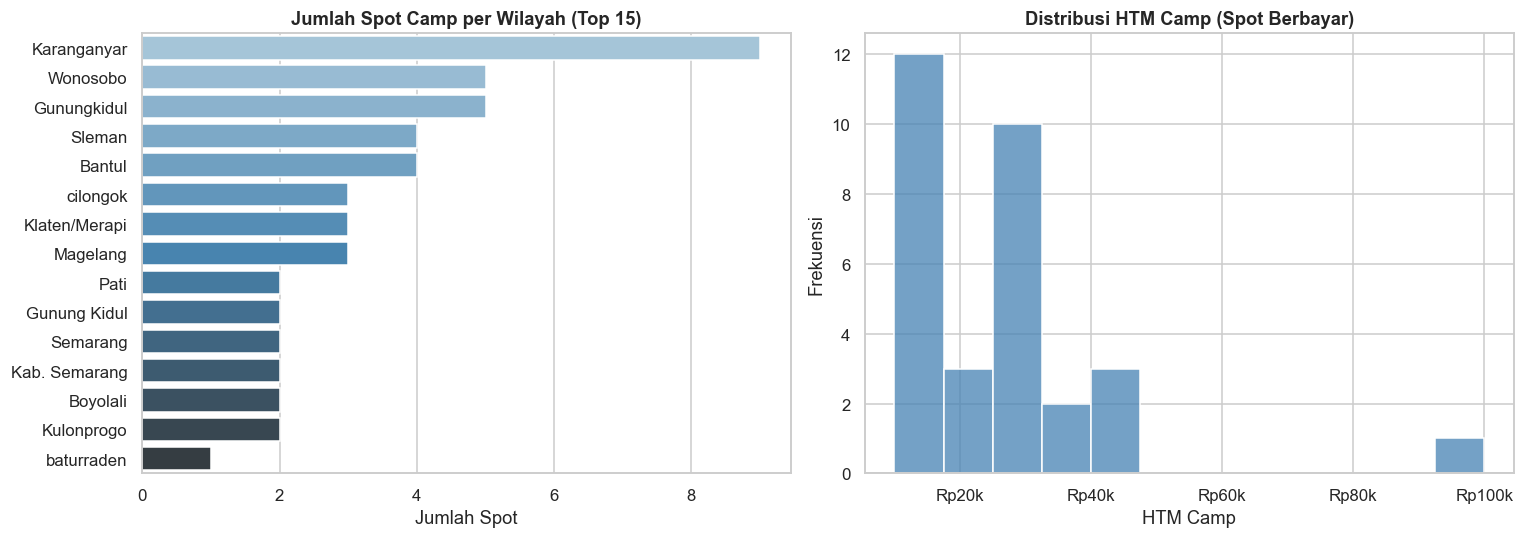


Statistik HTM Camp:
Jml Spot Berbayar         Rp31
Rata-rata             Rp25,387
Std Dev               Rp16,732
Minimum               Rp10,000
Q1                    Rp15,000
Median                Rp25,000
Q3                    Rp30,000
Maksimum             Rp100,000
Name: HTM_Camp_Num, dtype: object


In [7]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Plot 1: Jumlah Spot per Lokasi
lokasi_count = df_camp['Lokasi'].str.strip().value_counts().head(15)
sns.barplot(x=lokasi_count.values, y=lokasi_count.index, palette='Blues_d', ax=axes[0])
axes[0].set_title('Jumlah Spot Camp per Wilayah (Top 15)', fontsize=12, fontweight='bold')
axes[0].set_xlabel('Jumlah Spot')
axes[0].set_ylabel('')

# Plot 2: Distribusi HTM Camp
htm_valid = df_camp[df_camp['HTM_Camp_Num'] > 0]['HTM_Camp_Num']
sns.histplot(htm_valid, bins=12, color='steelblue', edgecolor='white', ax=axes[1])
axes[1].xaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f'Rp{int(x/1000)}k'))
axes[1].set_title('Distribusi HTM Camp (Spot Berbayar)', fontsize=12, fontweight='bold')
axes[1].set_xlabel('HTM Camp')
axes[1].set_ylabel('Frekuensi')

plt.tight_layout()
plt.savefig('eda_camp_01.png', bbox_inches='tight')
plt.show()

print('\nStatistik HTM Camp:')
print(htm_valid.describe().apply(lambda x: f'Rp{int(x):,}').rename(
    {'count':'Jml Spot Berbayar', 'mean':'Rata-rata', 'std':'Std Dev',
     'min':'Minimum', '25%':'Q1', '50%':'Median', '75%':'Q3', 'max':'Maksimum'}
))

### 3.2 EDA — Kelengkapan Fasilitas per Wilayah

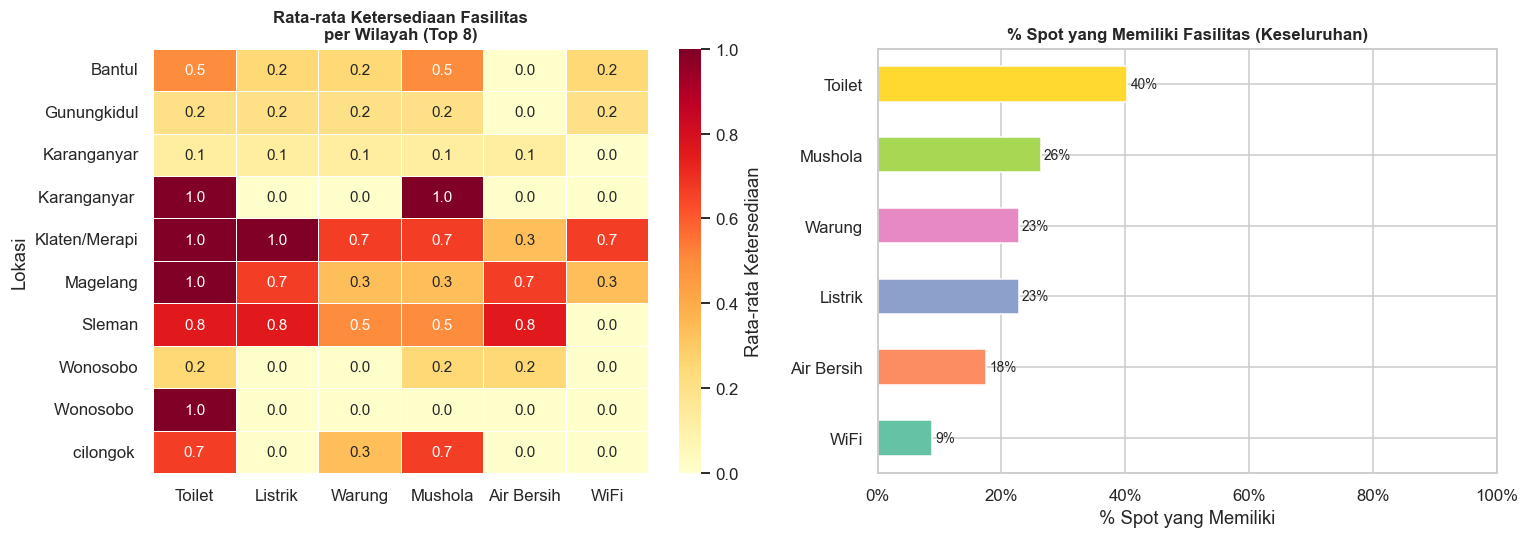

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Plot 1: Heatmap ketersediaan fasilitas per wilayah (top 8)
top_lokasi = df_camp['Lokasi'].str.strip().value_counts().head(8).index
df_top = df_camp[df_camp['Lokasi'].str.strip().isin(top_lokasi)]
heat_data = df_top.groupby('Lokasi')[fas_cols].mean().rename(
    columns={'Ada_Toilet':'Toilet', 'Ada_Listrik':'Listrik',
             'Ada_Warung':'Warung', 'Ada_Mushola':'Mushola',
             'Ada_Air':'Air Bersih', 'Ada_Wifi':'WiFi'}
)
sns.heatmap(heat_data, annot=True, fmt='.1f', cmap='YlOrRd',
            linewidths=0.5, cbar_kws={'label':'Rata-rata Ketersediaan'}, ax=axes[0])
axes[0].set_title('Rata-rata Ketersediaan Fasilitas\nper Wilayah (Top 8)', fontsize=11, fontweight='bold')

# Plot 2: Persen fasilitas dominan keseluruhan
fas_pct = df_camp[fas_cols].mean() * 100
fas_pct.index = ['Toilet', 'Listrik', 'Warung', 'Mushola', 'Air Bersih', 'WiFi']
colors = sns.color_palette('Set2', len(fas_pct))
fas_pct.sort_values(ascending=True).plot(kind='barh', ax=axes[1], color=colors, edgecolor='white')
axes[1].set_xlim(0, 100)
axes[1].set_title('% Spot yang Memiliki Fasilitas (Keseluruhan)', fontsize=11, fontweight='bold')
axes[1].set_xlabel('% Spot yang Memiliki')
axes[1].xaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f'{int(x)}%'))
for i, val in enumerate(fas_pct.sort_values(ascending=True)):
    axes[1].text(val + 0.5, i, f'{val:.0f}%', va='center', fontsize=9)

plt.tight_layout()
plt.savefig('eda_camp_02.png', bbox_inches='tight')
plt.show()

### 3.3 EDA — Profil Tag Suasana Spot Camping

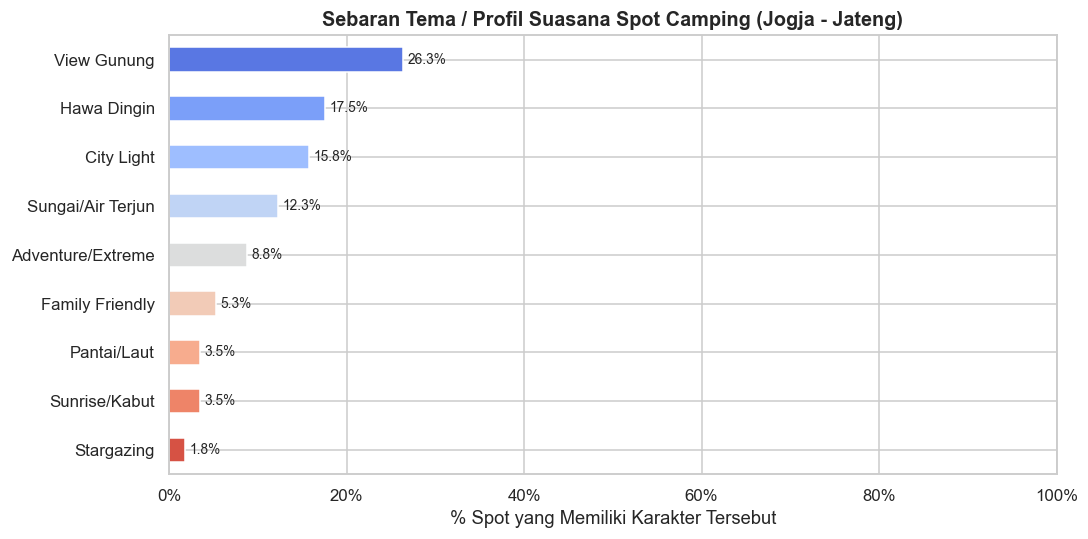

In [9]:
tag_cols = ['Tag_View_Gunung', 'Tag_Sunrise', 'Tag_Citylight',
            'Tag_Pantai', 'Tag_Sungai', 'Tag_Dingin',
            'Tag_Family', 'Tag_Adventure', 'Tag_Stargazing']

tag_pct = df_camp[tag_cols].mean() * 100
tag_pct.index = ['View Gunung', 'Sunrise/Kabut', 'City Light',
                 'Pantai/Laut', 'Sungai/Air Terjun', 'Hawa Dingin',
                 'Family Friendly', 'Adventure/Extreme', 'Stargazing']

fig, ax = plt.subplots(figsize=(10, 5))
palette = sns.color_palette('coolwarm_r', len(tag_pct))
tag_pct.sort_values(ascending=True).plot(kind='barh', ax=ax, color=palette, edgecolor='white')
ax.set_xlim(0, 100)
ax.set_title('Sebaran Tema / Profil Suasana Spot Camping (Jogja - Jateng)', fontsize=13, fontweight='bold')
ax.set_xlabel('% Spot yang Memiliki Karakter Tersebut')
ax.xaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f'{int(x)}%'))
for i, val in enumerate(tag_pct.sort_values(ascending=True)):
    ax.text(val + 0.5, i, f'{val:.1f}%', va='center', fontsize=9)

plt.tight_layout()
plt.savefig('eda_camp_03.png', bbox_inches='tight')
plt.show()

### 3.4 EDA — Distribusi Harga Gear per Kategori

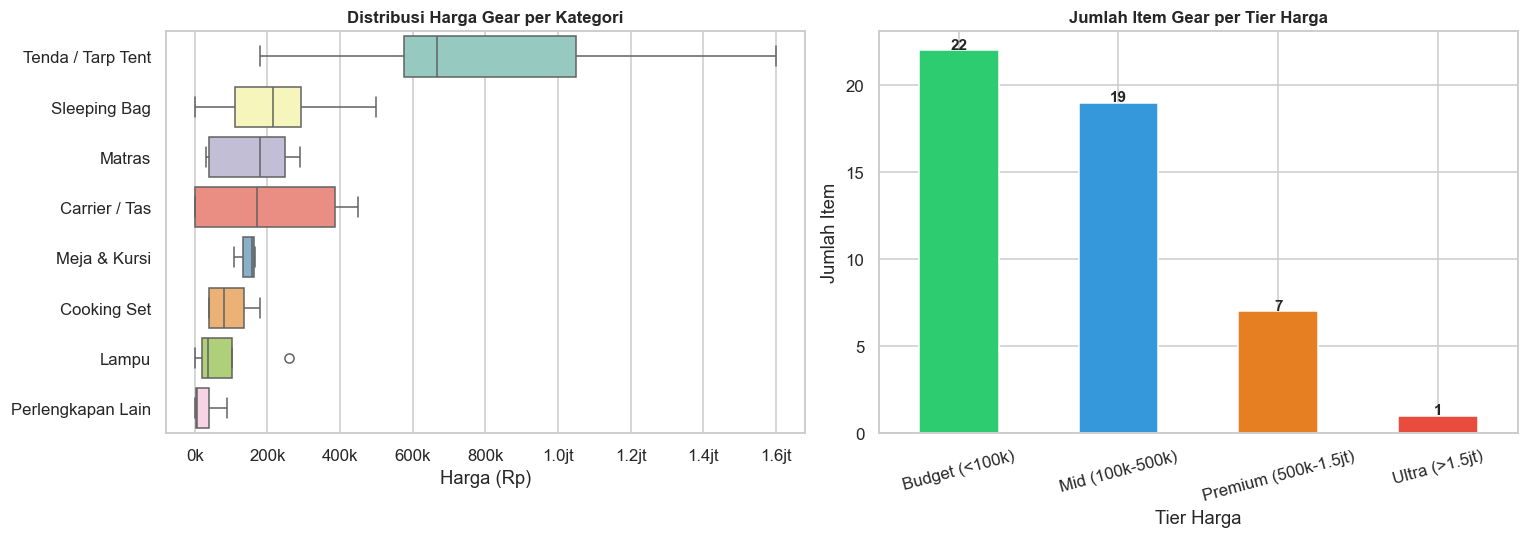


Statistik Harga Gear per Kategori:
                   Jml Item   Min (Rp) Median (Rp)     Max (Rp)
Kategori                                                       
Carrier / Tas             6      Rp285   Rp170,227    Rp450,000
Cooking Set               8   Rp39,000    Rp80,000    Rp180,000
Lampu                     4      Rp140    Rp37,500    Rp260,000
Matras                    5   Rp30,000   Rp180,000    Rp290,000
Meja & Kursi              3  Rp108,000   Rp159,000    Rp166,000
Perlengkapan Lain         7       Rp20     Rp7,000     Rp90,000
Sleeping Bag              6        Rp8   Rp215,000    Rp500,000
Tenda / Tarp Tent        10  Rp180,000   Rp667,000  Rp1,600,000


In [10]:
df_gear_valid = df_gear[df_gear['Harga_Num'].notna()].copy()

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Plot 1: Boxplot harga per kategori
cat_order = df_gear_valid.groupby('Kategori')['Harga_Num'].median().sort_values(ascending=False).index
sns.boxplot(data=df_gear_valid, x='Harga_Num', y='Kategori', order=cat_order,
            palette='Set3', ax=axes[0])
axes[0].xaxis.set_major_formatter(mticker.FuncFormatter(
    lambda x, _: f'{int(x/1000)}k' if x < 1_000_000 else f'{x/1_000_000:.1f}jt'))
axes[0].set_title('Distribusi Harga Gear per Kategori', fontsize=11, fontweight='bold')
axes[0].set_xlabel('Harga (Rp)')
axes[0].set_ylabel('')

# Plot 2: Jumlah item per tier harga
tier_order = ['Budget (<100k)', 'Mid (100k-500k)', 'Premium (500k-1.5jt)', 'Ultra (>1.5jt)']
tier_count = df_gear_valid['Tier_Harga'].value_counts().reindex(tier_order, fill_value=0)
colors_t = ['#2ecc71', '#3498db', '#e67e22', '#e74c3c']
tier_count.plot(kind='bar', ax=axes[1], color=colors_t, edgecolor='white', rot=15)
axes[1].set_title('Jumlah Item Gear per Tier Harga', fontsize=11, fontweight='bold')
axes[1].set_xlabel('Tier Harga')
axes[1].set_ylabel('Jumlah Item')
for i, v in enumerate(tier_count):
    axes[1].text(i, v + 0.1, str(v), ha='center', fontsize=10, fontweight='bold')

plt.tight_layout()
plt.savefig('eda_gear_01.png', bbox_inches='tight')
plt.show()

print('\nStatistik Harga Gear per Kategori:')
stats = df_gear_valid.groupby('Kategori')['Harga_Num'].agg(['count','min','median','max'])
stats.columns = ['Jml Item', 'Min (Rp)', 'Median (Rp)', 'Max (Rp)']
stats_fmt = stats.copy()
for col in ['Min (Rp)', 'Median (Rp)', 'Max (Rp)']:
    stats_fmt[col] = stats_fmt[col].apply(lambda x: f'Rp{int(x):,}')
print(stats_fmt.to_string())

---
## 4. Segmentasi Spot Camping — K-Means Clustering

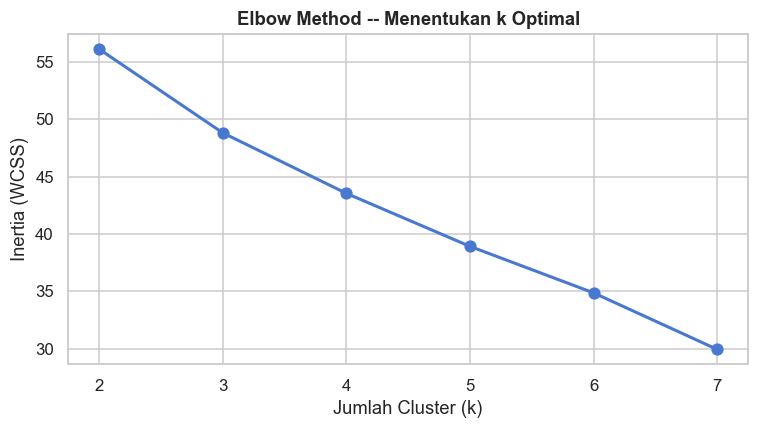

In [11]:
from sklearn.preprocessing import MinMaxScaler
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA

cluster_features = [
    'HTM_Total_Num', 'Jml_Fasilitas',
    'Ada_Listrik', 'Ada_Air', 'Ada_Wifi', 'Ada_Warung',
    'Tag_View_Gunung', 'Tag_Sunrise', 'Tag_Citylight',
    'Tag_Pantai', 'Tag_Sungai', 'Tag_Dingin',
    'Tag_Family', 'Tag_Adventure'
]

df_cluster = df_camp[cluster_features].fillna(0).copy()
scaler = MinMaxScaler()
X_scaled = scaler.fit_transform(df_cluster)

# Elbow Method
inertias = []
K_range = range(2, 8)
for k in K_range:
    km = KMeans(n_clusters=k, random_state=42, n_init=10)
    km.fit(X_scaled)
    inertias.append(km.inertia_)

fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(K_range, inertias, 'bo-', linewidth=2, markersize=7)
ax.set_xlabel('Jumlah Cluster (k)')
ax.set_ylabel('Inertia (WCSS)')
ax.set_title('Elbow Method -- Menentukan k Optimal', fontsize=12, fontweight='bold')
ax.set_xticks(list(K_range))
plt.tight_layout()
plt.savefig('eda_elbow.png', bbox_inches='tight')
plt.show()

In [12]:
# K-Means dengan k=3
K_BEST = 3
km_final = KMeans(n_clusters=K_BEST, random_state=42, n_init=10)
df_camp['Cluster'] = km_final.fit_predict(X_scaled)

centroid_df = pd.DataFrame(scaler.inverse_transform(km_final.cluster_centers_),
                            columns=cluster_features)

# Otomatis tentukan label berdasarkan nilai centroid
scores = {
    i: {
        'family_score':    centroid_df.loc[i, ['Ada_Listrik','Ada_Wifi','Ada_Air','Tag_Family','Jml_Fasilitas']].mean(),
        'adventure_score': centroid_df.loc[i, ['Tag_Adventure','Tag_Sungai']].mean(),
        'scenic_score':    centroid_df.loc[i, ['Tag_View_Gunung','Tag_Sunrise','Tag_Citylight','Tag_Dingin']].mean(),
    }
    for i in range(K_BEST)
}

label_map = {}
used_labels = set()
for i in range(K_BEST):
    best = max(scores[i], key=scores[i].get)
    name = {
        'family_score':    'Family & Fasilitas Lengkap',
        'adventure_score': 'Adventure & Wild',
        'scenic_score':    'Scenic & Pemandangan'
    }[best]
    if name in used_labels:
        name = f'Cluster {i}'
    label_map[i] = name
    used_labels.add(name)

df_camp['Tipe_Camp'] = df_camp['Cluster'].map(label_map)

print('Distribusi Cluster:')
print(df_camp['Tipe_Camp'].value_counts())
print('\nSample per Cluster:')
print(df_camp.groupby('Tipe_Camp')[['Nama', 'Lokasi']].apply(lambda g: g.head(3)).to_string())

Distribusi Cluster:
Tipe_Camp
Adventure & Wild              39
Family & Fasilitas Lengkap    11
Cluster 2                      7
Name: count, dtype: int64

Sample per Cluster:
                                                    Nama         Lokasi
Tipe_Camp                                                              
Adventure & Wild           0                        Nama  Lokasi/Daerah
                           1       Potrobayan River Camp         Bantul
                           3         Watu Mabur Mangunan         Bantul
Cluster 2                  13      Gunung Gajah Telomoyo  Kab. Semarang
                           28        Pinea Forest Mangli       Magelang
                           30  Camp Ground Waduk Gembong           Pati
Family & Fasilitas Lengkap 2          Hutan Pinus Becici         Bantul
                           10           Pantai Watukodok    Gunungkidul
                           21              Bukit Sekipan    Karanganyar


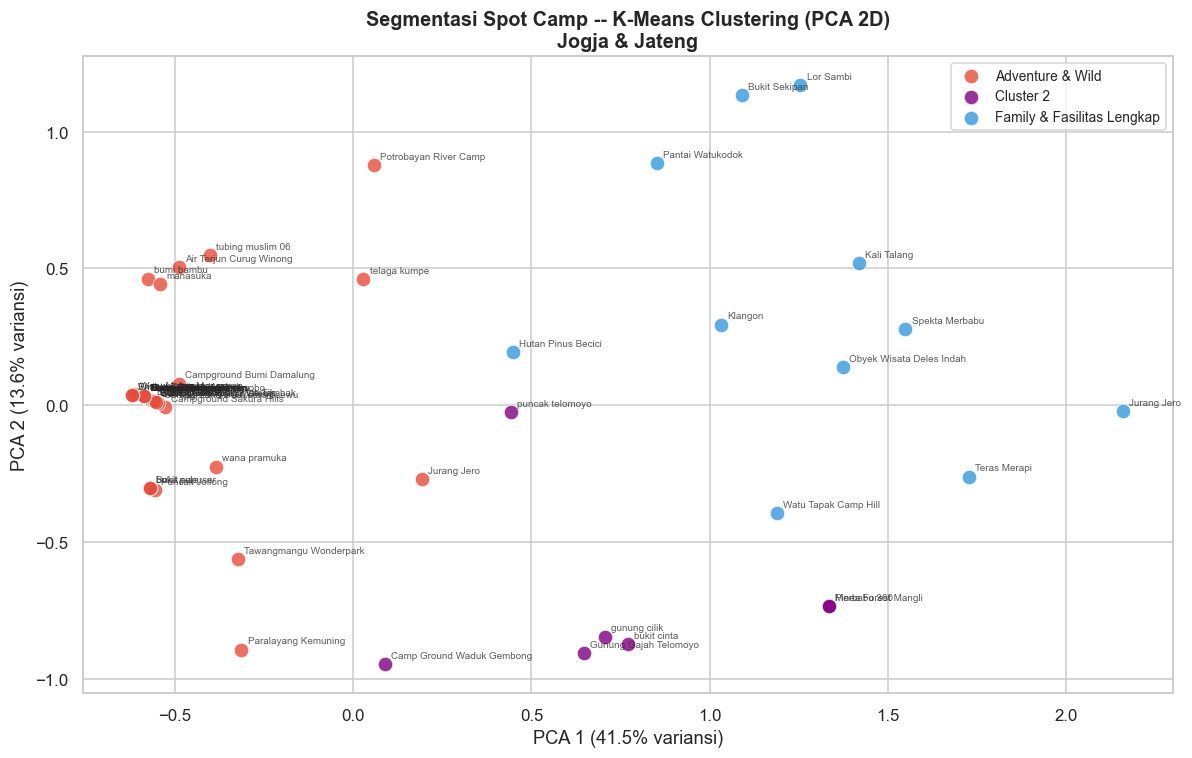

In [13]:
# Visualisasi Cluster dengan PCA 2D
pca = PCA(n_components=2, random_state=42)
X_pca = pca.fit_transform(X_scaled)

df_camp['PCA_1'] = X_pca[:, 0]
df_camp['PCA_2'] = X_pca[:, 1]

palette_cluster = {
    'Family & Fasilitas Lengkap': '#3498db',
    'Adventure & Wild':           '#e74c3c',
    'Scenic & Pemandangan':       '#2ecc71',
    'Cluster 0': 'gray', 'Cluster 1': 'orange', 'Cluster 2': 'purple'
}

fig, ax = plt.subplots(figsize=(11, 7))
for tipe, grp in df_camp.groupby('Tipe_Camp'):
    color = palette_cluster.get(tipe, 'gray')
    ax.scatter(grp['PCA_1'], grp['PCA_2'], label=tipe, color=color,
               s=90, alpha=0.8, edgecolors='white', linewidths=0.6)
    for _, row in grp.iterrows():
        ax.annotate(row['Nama'], (row['PCA_1'], row['PCA_2']),
                    textcoords='offset points', xytext=(4, 4),
                    fontsize=6.5, alpha=0.75)

ax.set_title(f'Segmentasi Spot Camp -- K-Means Clustering (PCA 2D)\nJogja & Jateng', fontsize=13, fontweight='bold')
ax.set_xlabel(f'PCA 1 ({pca.explained_variance_ratio_[0]*100:.1f}% variansi)')
ax.set_ylabel(f'PCA 2 ({pca.explained_variance_ratio_[1]*100:.1f}% variansi)')
ax.legend(fontsize=9, framealpha=0.8)
plt.tight_layout()
plt.savefig('cluster_pca.png', bbox_inches='tight')
plt.show()

---
## 5. Matriks Relasi — Pemetaan Profil Spot ↔ Rekomendasi Gear

In [14]:
# Aturan rule-based: Kondisi Spot -> Kategori Gear yang Dibutuhkan
GEAR_RULES = {
    'tenda': {
        'Family & Fasilitas Lengkap': ['Decathlon MH100', 'Big Adventure Tambora', 'LWY compass', 'Wildshell Navageo'],
        'Adventure & Wild':           ['TarpTent Wallhike Calabura', 'TarpTent Wallhike Goramy', 'Flysheet Saffar'],
        'Scenic & Pemandangan':       ['Naturehike Cloud Up 2', 'Wildshell Sembalun Pro', 'Basic Pollux'],
    },
    'sleeping_bag': {
        'dingin': ['Baseking Bulang', 'Bigadventure Natuna Reborn', 'Baseking Microfiber'],
        'sedang': ['Makalu Alpsdream 400-700', 'Bigadventure Natuna Reborn'],
    },
    'matras': {
        'standar': ['Matras Karet Biasa', 'Eiger Dream Foam Pad'],
        'premium': ['Matras Angin Venturis', 'Big Adventure Purukambera Sleeping Pad'],
    },
    'cooking': {
        'standar':    ['Nesting DS101', 'Kompor Dhaulagiri', 'sumbu langit cooking set'],
        'ultralight': ['Kompor Canister BRS3000T', 'Kompor Ultralight', 'Adaptor kompor canister'],
    },
}

print('Matriks aturan gear terdefinisi.')
print('Kategori gear:', list(GEAR_RULES.keys()))

Matriks aturan gear terdefinisi.
Kategori gear: ['tenda', 'sleeping_bag', 'matras', 'cooking']


---
## 6. Smart Camping Planner — Demo Prototype

In [15]:
def camping_planner(
    preferensi_lokasi: str = '',
    preferensi_suasana: list = None,
    butuh_listrik: bool = False,
    butuh_wifi: bool = False,
    budget_tiket: int = 50_000,
    budget_gear: int = 2_000_000,
    top_n: int = 5,
):
    """
    Smart Camping Planner -- YuruCamp
    Input  : preferensi lokasi, suasana, kebutuhan fasilitas, budget
    Output : Top-N rekomendasi spot + checklist gear + estimasi total biaya

    preferensi_suasana pilihan: 'view_gunung', 'sunrise', 'citylight',
                                'pantai', 'sungai', 'dingin',
                                'family', 'adventure', 'stargazing'
    """
    if preferensi_suasana is None:
        preferensi_suasana = []

    df = df_camp.copy()

    # FILTER 1: Lokasi
    if preferensi_lokasi:
        df = df[df['Lokasi'].str.lower().str.contains(preferensi_lokasi.lower(), na=False)]

    # FILTER 2: Budget tiket
    df = df[df['HTM_Total_Num'] <= budget_tiket]

    # FILTER 3: Fasilitas wajib
    if butuh_listrik:
        df = df[df['Ada_Listrik'] == 1]
    if butuh_wifi:
        df = df[df['Ada_Wifi'] == 1]

    if df.empty:
        print('Tidak ada spot yang sesuai kriteria. Coba longgarkan filter.')
        return

    # SCORING berdasarkan preferensi suasana
    suasana_map = {
        'view_gunung': 'Tag_View_Gunung', 'sunrise': 'Tag_Sunrise',
        'citylight':   'Tag_Citylight',   'pantai':  'Tag_Pantai',
        'sungai':      'Tag_Sungai',      'dingin':  'Tag_Dingin',
        'family':      'Tag_Family',      'adventure':'Tag_Adventure',
        'stargazing':  'Tag_Stargazing',
    }

    df = df.copy()
    df['Score'] = df['Jml_Fasilitas'] * 0.5
    for pref in preferensi_suasana:
        col = suasana_map.get(pref)
        if col and col in df.columns:
            df['Score'] += df[col] * 2

    df = df.sort_values('Score', ascending=False).head(top_n)

    # =========== OUTPUT ===========
    print('=' * 65)
    print('  YURUCAMP -- SMART CAMPING PLANNER RESULTS')
    print('=' * 65)
    print(f'  Preferensi : {preferensi_suasana or "Semua suasana"}')
    print(f'  Budget tiket : Rp{budget_tiket:,}/orang | Budget gear : Rp{budget_gear:,}')
    print('=' * 65)

    for rank, (_, row) in enumerate(df.iterrows(), 1):
        htm_total = int(row['HTM_Total_Num'])
        maps_link = row['Maps'] if pd.notna(row['Maps']) and str(row['Maps']).startswith('http') else 'Tidak tersedia'
        print(f"\n{'#' * 50}")
        print(f"  Rank #{rank}: {row['Nama']}")
        print(f"  Lokasi     : {row['Lokasi']}")
        print(f"  HTM Total  : Rp{htm_total:,}/orang")
        print(f"  Tipe Camp  : {row['Tipe_Camp']}")
        print(f"  Spot Keren : {row['Spot_Menarik'] or '-'}")
        print(f"  Fasilitas  : {row['Fasilitas'] or 'Tidak tercatat'}")
        print(f"  Info Penting : {row['Info_Tambahan'] or '-'}")
        print(f"  Maps       : {maps_link}")

    # Tentukan kondisi dominan dari spot yang direkomendasikan
    is_dingin    = df['Tag_Dingin'].mean() > 0.4
    is_adventure = df['Tag_Adventure'].mean() > 0.3
    is_family    = df['Tag_Family'].mean() > 0.3 or butuh_listrik

    tipe_key = (
        'Family & Fasilitas Lengkap' if is_family else
        'Adventure & Wild' if is_adventure else
        'Scenic & Pemandangan'
    )
    sb_key   = 'dingin' if is_dingin else 'sedang'
    cook_key = 'ultralight' if is_adventure else 'standar'

    tenda_rec  = GEAR_RULES['tenda'].get(tipe_key, ['Naturehike Cloud Up 2'])
    sb_rec     = GEAR_RULES['sleeping_bag'].get(sb_key, [])
    matras_rec = GEAR_RULES['matras']['premium' if is_dingin else 'standar']
    cook_rec   = GEAR_RULES['cooking'].get(cook_key, [])

    def get_gear_price(nama_list):
        return df_gear[df_gear['Nama'].isin(nama_list)]

    def pick_within_budget(gear_df, remaining):
        valid = gear_df[gear_df['Harga_Num'] <= remaining].sort_values('Harga_Num')
        if valid.empty:
            valid = gear_df.sort_values('Harga_Num')
        return valid.iloc[0] if not valid.empty else None

    print(f"\n{'=' * 65}")
    print('  REKOMENDASI PAKET GEAR (Budget-Aware)')
    print('=' * 65)

    total_gear  = 0
    sisa_budget = budget_gear
    gear_packs  = [
        ('Tenda',         get_gear_price(tenda_rec)),
        ('Sleeping Bag',  get_gear_price(sb_rec)),
        ('Matras',        get_gear_price(matras_rec)),
        ('Cooking Set',   get_gear_price(cook_rec)),
    ]

    for label, gdf in gear_packs:
        pick = pick_within_budget(gdf, sisa_budget)
        if pick is not None:
            harga = pick['Harga_Num'] if not pd.isna(pick['Harga_Num']) else 0
            sisa_budget -= harga
            total_gear  += harga
            print(f"  {label:<18} -> {pick['Nama']:<35} Rp{int(harga):>10,}  [{pick['Tier_Harga']}]")
        else:
            print(f"  {label:<18} -> (tidak ada data harga)")

    # Basic extras
    extras = [('Lampu Lentera', 50_000), ('Carrier (est.)', 450_000), ('Spork + Pasak', 15_000)]
    for nama, harga in extras:
        total_gear += harga
        print(f"  {nama:<18} -> {'(estimasi)':>35}   Rp{harga:>10,}")

    htm_min = int(df['HTM_Total_Num'].min())
    grand_total = total_gear + htm_min

    print('-' * 65)
    print(f"  {'TOTAL ESTIMASI GEAR':<50} Rp{int(total_gear):>10,}")
    print(f"  {'HTM Camp (1 malam, 1 orang)':<50} Rp{htm_min:>10,}")
    print('=' * 65)
    print(f"  {'GRAND TOTAL ESTIMASI':<50} Rp{int(grand_total):>10,}")
    print('=' * 65)

    if total_gear > budget_gear:
        kelebihan = total_gear - budget_gear
        print(f"\n  PERINGATAN: Melebihi budget gear Rp{int(kelebihan):,}. Pertimbangkan sewa/pinjam beberapa item!")
    else:
        sisa = budget_gear - total_gear
        print(f"\n  OK: Masih ada sisa budget gear Rp{int(sisa):,} (bisa untuk logistik/makanan camping!)")

print('Fungsi camping_planner() siap digunakan!')

Fungsi camping_planner() siap digunakan!


### 6.1 Demo Scenario 1 — View Gunung + Hawa Dingin, Budget Hemat

In [16]:
camping_planner(
    preferensi_lokasi='',
    preferensi_suasana=['view_gunung', 'sunrise', 'dingin'],
    butuh_listrik=False,
    butuh_wifi=False,
    budget_tiket=30_000,
    budget_gear=1_500_000,
    top_n=3
)

  YURUCAMP -- SMART CAMPING PLANNER RESULTS
  Preferensi : ['view_gunung', 'sunrise', 'dingin']
  Budget tiket : Rp30,000/orang | Budget gear : Rp1,500,000

##################################################
  Rank #1: Teras Merapi
  Lokasi     : Sleman
  HTM Total  : Rp20,000/orang
  Tipe Camp  : Family & Fasilitas Lengkap
  Spot Keren : - view puncak merapi dari jarak 5 km
- saat malam bisa melihat guguran lava
  Fasilitas  : toilet, mushola, warung, listrik, air bersih, kolam renang
  Info Penting : - ketinggan  di 900 mdpl, tidak terlalu dingin
- kolam renang langsung dari mata air 
  Maps       : https://maps.app.goo.gl/Uu9FRDf1rfgTZhi56

##################################################
  Rank #2: Jurang Jero
  Lokasi     : Magelang
  HTM Total  : Rp25,000/orang
  Tipe Camp  : Family & Fasilitas Lengkap
  Spot Keren : kaki gunung merapi sebelah barat, di dalam taman nasional gunung merapi
  Fasilitas  : toilet, air bersih, wifi, listrik, asuransi, lampu, warung 20 jam
  Info Pen

### 6.2 Demo Scenario 2 — Family Camping, Ada Listrik, Budget Fleksibel

In [17]:
camping_planner(
    preferensi_lokasi='Sleman',
    preferensi_suasana=['family', 'citylight'],
    butuh_listrik=True,
    butuh_wifi=False,
    budget_tiket=50_000,
    budget_gear=3_000_000,
    top_n=3
)

  YURUCAMP -- SMART CAMPING PLANNER RESULTS
  Preferensi : ['family', 'citylight']
  Budget tiket : Rp50,000/orang | Budget gear : Rp3,000,000

##################################################
  Rank #1: Teras Merapi
  Lokasi     : Sleman
  HTM Total  : Rp20,000/orang
  Tipe Camp  : Family & Fasilitas Lengkap
  Spot Keren : - view puncak merapi dari jarak 5 km
- saat malam bisa melihat guguran lava
  Fasilitas  : toilet, mushola, warung, listrik, air bersih, kolam renang
  Info Penting : - ketinggan  di 900 mdpl, tidak terlalu dingin
- kolam renang langsung dari mata air 
  Maps       : https://maps.app.goo.gl/Uu9FRDf1rfgTZhi56

  REKOMENDASI PAKET GEAR (Budget-Aware)
  Tenda              -> Decathlon MH100                     Rp   500,000  [Mid (100k-500k)]
  Sleeping Bag       -> Baseking Microfiber                 Rp   270,000  [Mid (100k-500k)]
  Matras             -> Matras Angin Venturis               Rp   250,000  [Mid (100k-500k)]
  Cooking Set        -> Nesting DS101        

### 6.3 Demo Scenario 3 — Adventure Wild, Tepi Sungai / Air Terjun

In [18]:
camping_planner(
    preferensi_lokasi='',
    preferensi_suasana=['adventure', 'sungai'],
    butuh_listrik=False,
    butuh_wifi=False,
    budget_tiket=20_000,
    budget_gear=1_000_000,
    top_n=3
)

  YURUCAMP -- SMART CAMPING PLANNER RESULTS
  Preferensi : ['adventure', 'sungai']
  Budget tiket : Rp20,000/orang | Budget gear : Rp1,000,000

##################################################
  Rank #1: Kali Talang
  Lokasi     : Klaten/Merapi
  HTM Total  : Rp15,000/orang
  Tipe Camp  : Family & Fasilitas Lengkap
  Spot Keren : Bg Gn Merapi , Hutan Alami , Tracking Jalur
  Fasilitas  : Listrik , Toilet, Warung, Mushola , Wifi
  Info Penting : nan
  Maps       : https://maps.app.goo.gl/DTJrCJSYDdsF6swW9

##################################################
  Rank #2: Potrobayan River Camp
  Lokasi     : Bantul
  HTM Total  : Rp15,000/orang
  Tipe Camp  : Adventure & Wild
  Spot Keren : Mancing 
  Fasilitas  : Toilet , Warung , Mushola
  Info Penting : Jangan camp terlalu dekat dengan sungai / lumayan panas suasananya
  Maps       : https://maps.app.goo.gl/pZpEQ47vpyssX24T8

##################################################
  Rank #3: tubing muslim 06
  Lokasi     : Karanganyar 
  HTM

---
## 7. Summary & Next Steps

### Yang sudah dibangun:
| Komponen | Status |
|---|---|
| Parsing & Reshaping Dataset Camp Area | Done |
| Reshaping Multi-Blok Dataset Gear ke Master Table | Done |
| Standardisasi HTM & Harga (String -> Numeric) | Done |
| Feature Engineering (Tag Fasilitas & Suasana) | Done |
| EDA Dataset Camp (Distribusi, HTM, Fasilitas, Tag Suasana) | Done |
| EDA Dataset Gear (Harga per Kategori, Tier) | Done |
| K-Means Clustering Segmentasi Spot (3 Tipe) | Done |
| Matriks Relasi Spot <-> Gear (Rule-Based Logic) | Done |
| Prototype Smart Camping Planner (3 Skenario Demo) | Done |

### Pengembangan Selanjutnya:
1. **Data Enrichment** -- Tambahkan kolom ketinggian mdpl, rating, jumlah ulasan dari Google Maps
2. **NLP Lanjutan** -- TF-IDF / Sentence Embedding untuk input teks bebas yang lebih natural
3. **Optimization** -- Integer Linear Programming (Knapsack) untuk paket gear paling optimal dalam budget
4. **Deployment** -- Bungkus menjadi Streamlit App / Gradio App untuk demo interaktif
5. **Dataset Expansion** -- Tambahkan spot luar Jogja-Jateng + data review pengguna nyata
6. **Collaborative Filtering** -- Jika ada data riwayat user, bangun sistem rekomendasi berbasis user similarity